In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Librería
import pandas as pd #Manipular datos
import glob #Busca archivos en carpetas
from sqlalchemy import create_engine, text #Conectar con SQL
import matplotlib.pyplot as plt #Visualizaciones
import seaborn as sns #Gráficos

### 🔵 Parte 1: Extracción y Diagnóstico (Extract)

In [5]:
RUTA = '/content/drive/MyDrive/Data/' #Ruta

# 1. Restaurantes
df_restaurantes = pd.read_csv(RUTA + 'restaurants.csv')

# 2. Menús:
archivos = sorted(glob.glob(RUTA + 'restaurant_menus_parte_*.csv'))
print(f"Archivos de menús encontrados: {len(archivos)}")

df_menus = pd.concat((pd.read_csv(f) for f in archivos), ignore_index=True)

# 3. Análsiis exploratorio --> Data Profiling
for nombre, df in [('RESTAURANTES', df_restaurantes), ('MENÚS', df_menus)]:
    print(f"\n===== {nombre} =====")
    print("Shape:", df.shape) #Imprimir dimensiones
    print("\nTipos de datos:\n", df.dtypes) #Tipos de datos
    print("\nValores nulos:\n", df.isnull().sum()) #Cantidad de valores nulos por columna

Archivos de menús encontrados: 10

===== RESTAURANTES =====
Shape: (63469, 11)

Tipos de datos:
 id                int64
position          int64
name             object
score           float64
ratings         float64
category         object
price_range      object
full_address     object
zip_code         object
lat             float64
lng             float64
dtype: object

Valores nulos:
 id                  0
position            0
name                0
score           28167
ratings         28167
category           85
price_range     10617
full_address      453
zip_code          517
lat                 0
lng                 0
dtype: int64

===== MENÚS =====
Shape: (836350, 5)

Tipos de datos:
 restaurant_id     int64
category         object
name             object
description      object
price            object
dtype: object

Valores nulos:
 restaurant_id         0
category              0
name                  1
description      200324
price                 0
dtype: int64


### 🟡 Parte 2: Ingeniería de Características y Limpieza (Transform)

#### df_restaurantes:

In [12]:
# 1. Mapeo de precios
#Diccionario
mapa_precios = {
    '$': 'Económico',
    '$$': 'Moderadamente caro',
    '$$$': 'Caro',
    '$$$$': 'Muy caro'
}
df_restaurantes['rango_de_precios'] = df_restaurantes['price_range'].map(mapa_precios) #Transformar a texto


# 2. Split --> Desanidado de Ubicaciones
partes = df_restaurantes['full_address'].str.split(',', expand = True)

# 2.1 Crear nuevas columnas
df_restaurantes['calle'] = partes[0].str.strip()
df_restaurantes['ciudad'] = partes[1].str.strip()
df_restaurantes['estado_zip'] = (partes[2].str.strip() + ' ' + partes[3].str.strip())


# 3. Filtro de calidad y minúsculas
df_restaurantes = df_restaurantes[df_restaurantes['score'].notnull() & (df_restaurantes['score'] != 0)] #Se queda los que no son vacíos
df_restaurantes['category'] = df_restaurantes['category'].str.lower() #Pasando a minúscula

#### df_menus

In [16]:
# Quitar " USD", cambiar coma por punto, castear a float
df_menus['price'] = (df_menus['price'].astype(str)
                     .str.replace(' USD', '', regex = False) #Elimina texto + Reemplaza + Castea
                     .str.replace(',', '.', regex = False)
                     .astype(float))

df_menus = df_menus[df_menus['price'].notnull() & (df_menus['price'] != 0.0)] #Elimina los ítems del menú con precio igual a 0.0 o nulos.

In [18]:
#Validando
print(df_menus['price'].dtype) #float
print(df_menus.shape)
df_menus.head()

float64
(798799, 5)


,restaurant_id,category,name,description,price
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99
2,1,Extra Large Pizza,Extra Large Pepperoni,Whole pie.,14.99
3,1,Extra Large Pizza,Extra Large BBQ Chicken &amp; Bacon,Whole Pie,15.99
4,1,Extra Large Pizza,Extra Large 5 Cheese,Whole pie.,14.99


#### Optimización y Cruce (Control de Memoria RAM):

In [19]:
# Solo restaurantes con más de 100 calificaciones
df_restaurantes = df_restaurantes[df_restaurantes['ratings'] > 100]

In [22]:
# INNER JOIN
df_master = pd.merge(df_restaurantes, df_menus,
                     left_on='id', right_on='restaurant_id', how='inner',
                     suffixes=('_rest', '_menu')) #Diferenciación
print(df_master.shape)
df_master.head()

(63221, 20)


,id,position,name_rest,score,ratings,category_rest,price_range,full_address,zip_code,lat,lng,rango_de_precios,calle,ciudad,estado_zip,restaurant_id,category_menu,name_menu,description,price
0,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Spring Roll,"Three rolls. Shrimps, sliced pork, vermicelli ...",6.99
1,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Egg Roll,"Pork, carrot, bean thread noodles, and are wra...",6.50
2,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Grilled Pork,Foot long.,9.50
3,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,House Special,"Rice noodle with steak, rare, flank, brisket, ...",10.95
4,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Rice Noodle with Rare Steak,NaN,10.95


### 🟢 Parte 3: Carga a Base de Datos (Load)

In [24]:
# BD SQlite local
engine = create_engine('sqlite:///delivery_insights.db')
# Guardar tabla en mi drive
# engine = create_engine('sqlite:////content/drive/MyDrive/Data/delivery_insights.db')

#Tabla final
df_master.to_sql('master_food_data', con=engine, if_exists='replace', index=False)
print("✅ Tabla cargada ---> master_food_data")

✅ Tabla cargada ---> master_food_data


In [27]:
#Validando tabla cargada
with engine.connect() as conn:
    df_vista = pd.read_sql(text("SELECT * FROM master_food_data LIMIT 5"), conn)
display(df_vista)

,id,position,name_rest,score,ratings,category_rest,price_range,full_address,zip_code,lat,lng,rango_de_precios,calle,ciudad,estado_zip,restaurant_id,category_menu,name_menu,description,price
0,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Spring Roll,"Three rolls. Shrimps, sliced pork, vermicelli ...",6.99
1,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Egg Roll,"Pork, carrot, bean thread noodles, and are wra...",6.50
2,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Grilled Pork,Foot long.,9.50
3,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,House Special,"Rice noodle with steak, rare, flank, brisket, ...",10.95
4,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",$,"4756 S 27th St, Milwaukee, WI, 53221",53221,42.958143,-87.94815,Económico,4756 S 27th St,Milwaukee,WI 53221,1739,Picked for you,Rice Noodle with Rare Steak,None,10.95


### 🔴 Parte 4: Business Intelligence: Reporte al CEO (SQL + Visualización)

#### Pregunta 1: Penetración Geográfica --> Top 5 ciudades


SELECT ciudad AS Ciudad, COUNT(DISTINCT id) AS Total_restaurantes
FROM master_food_data
GROUP BY ciudad
ORDER BY total_restaurantes DESC --TOP 5
LIMIT 5



,Ciudad,Total_restaurantes
0,Milwaukee,122
1,Seattle,119
2,Lynnwood,40
3,Everett,32
4,Bellevue,28


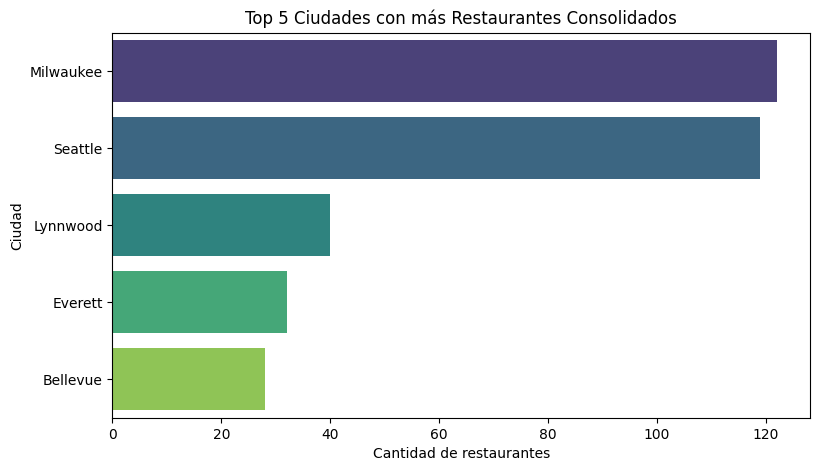

In [34]:
query1 = """
SELECT ciudad AS Ciudad, COUNT(DISTINCT id) AS Total_restaurantes
FROM master_food_data
GROUP BY ciudad
ORDER BY total_restaurantes DESC --TOP 5
LIMIT 5
"""
with engine.connect() as conn:
    df_q1 = pd.read_sql(text(query1), conn)
print(query1)
display(df_q1) #Dataframe

plt.figure(figsize=(9, 5))
#sns.barplot(data=df_q1, x='total_restaurantes', y='ciudad', palette='viridis')
sns.barplot(data=df_q1, x ='Total_restaurantes', y ='Ciudad',
            hue='Ciudad', palette='viridis', legend=False)
plt.title('Top 5 Ciudades con más Restaurantes Consolidados')
plt.xlabel('Cantidad de restaurantes')
plt.ylabel('Ciudad')
plt.show()

Conclusión 1: Milwaukee (122) y Seattle (119) lideran con amplia ventaja sobre Lynnwood (40), Everett (32) y Bellevue (28): son las ciudades más competitivas

#### Pregunta 2: Análisis de Oportunidad de Precio

,rango_de_precios,total
0,Caro,4
1,Económico,450
2,Moderadamente caro,157


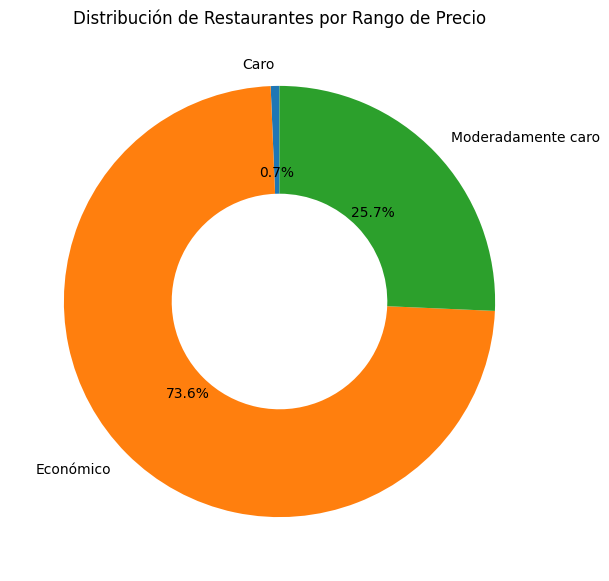

In [40]:
query2 = """
SELECT rango_de_precios, COUNT(DISTINCT id) AS total
FROM master_food_data
WHERE rango_de_precios IS NOT NULL
GROUP BY rango_de_precios
"""
with engine.connect() as conn:
    df_q2 = pd.read_sql(text(query2), conn)
display(df_q2)

plt.figure(figsize=(7, 7))
plt.pie(df_q2['total'], labels=df_q2['rango_de_precios'], autopct='%1.1f%%',
        startangle=90, wedgeprops={'width': 0.5})
plt.title('Distribución de Restaurantes por Rango de Precio')
plt.show()

Conclusión 2: El CEO no tiene razón: la mayoría de los restaurantes son "Económico" (74%), seguidos de "Moderadamente caro" (26%), mientras que "Caro"

### Pregunta 3: Estrategia de Menú por Ciudad

,ciudad,precio_promedio
0,Seattle,11.98
1,Lynnwood,10.82
2,Milwaukee,9.53


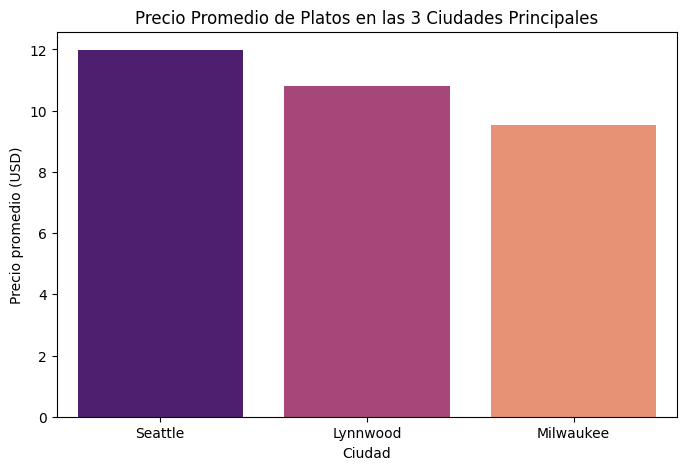

In [43]:
query3 = """
SELECT ciudad, ROUND(AVG(price), 2) AS precio_promedio
FROM master_food_data
WHERE ciudad IN (
    SELECT ciudad FROM (
        SELECT ciudad, COUNT(DISTINCT id) AS n
        FROM master_food_data
        GROUP BY ciudad
        ORDER BY n DESC
        LIMIT 3
    )
)
GROUP BY ciudad
ORDER BY precio_promedio DESC
"""
with engine.connect() as conn:
    df_q3 = pd.read_sql(text(query3), conn)
display(df_q3)

plt.figure(figsize=(8, 5))
#sns.barplot(data=df_q3, x='ciudad', y='precio_promedio', palette='magma')
sns.barplot(data=df_q3, x='ciudad', y='precio_promedio',
            hue='ciudad', palette='magma', legend = False)
plt.title('Precio Promedio de Platos en las 3 Ciudades Principales')
plt.xlabel('Ciudad')
plt.ylabel('Precio promedio (USD)')
plt.show()

Conclusión 3: Seattle (#2 en cantidad de restaurantes) es la ciudad más cara para comer, con un precio promedio de $12 por plato.

### Pregunta 4: La Pregunta del Millón (Correlación Precio-Calidad):

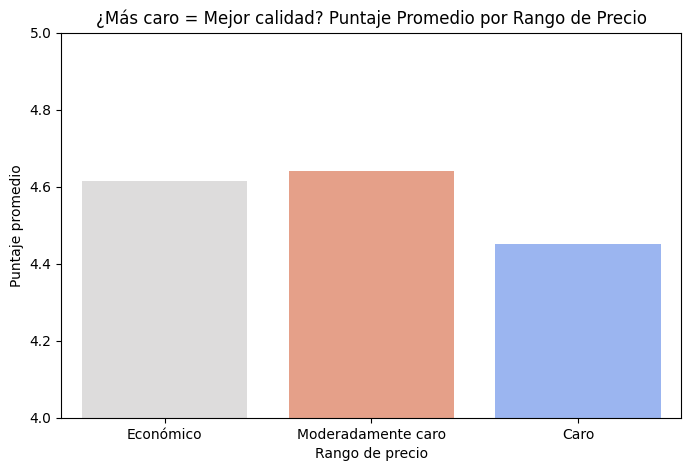

In [45]:
query4 = """
SELECT rango_de_precios, ROUND(AVG(score), 3) AS score_promedio
FROM (
    SELECT DISTINCT id, rango_de_precios, score
    FROM master_food_data
    WHERE rango_de_precios IS NOT NULL
)
GROUP BY rango_de_precios
"""
with engine.connect() as conn:
    df_q4 = pd.read_sql(text(query4), conn)

# Ordenar de menor a mayor precio
orden = ['Económico', 'Moderadamente caro', 'Caro', 'Muy caro']
df_q4['rango_de_precios'] = df_q4['rango_de_precios'].astype(str)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_q4, x='rango_de_precios', y='score_promedio',
            hue='rango_de_precios', palette='coolwarm', legend=False,
            order=['Económico', 'Moderadamente caro', 'Caro'])
plt.title('¿Más caro = Mejor calidad? Puntaje Promedio por Rango de Precio')
plt.xlabel('Rango de precio')
plt.ylabel('Puntaje promedio')
plt.ylim(4, 5)
plt.show()

In [46]:
with engine.connect() as conn:
    print(pd.read_sql(text("""
        SELECT rango_de_precios, COUNT(DISTINCT id) AS n
        FROM master_food_data
        GROUP BY rango_de_precios
    """), conn))

     rango_de_precios    n
0                None   60
1                Caro    4
2           Económico  450
3  Moderadamente caro  157


Conclusión 4: Más caro no garantiza mejor calidad: el puntaje es similar en "Económico" (4.62) y "Moderadamente caro" (4.64), y baja en "Caro" (4.45).